# Chapter 2: Teaching a model to read categories: is Surat twice Pune?
*Encoding categoricals; scaling numerics; which models care · also searched as: one-hot
encoding, label encoding, standard scaling, feature scaling*

A model reads numbers. Kalpa's table has words (city, job, tier) and numbers on very
different scales (spend in rupees, visits in single digits). How a word becomes a number,
and whether a number is rescaled, decides what the model can learn, and the right choice
depends on the model family.

**Who needs the answer.** The implementation engineer, who writes the pipeline the scoring
service runs every night, and Kavya, who reads the model's coefficients.

**The questions on the way.** What goes wrong when cities become 1, 2 and 3? What does
one-hot encoding do instead? Why does spend in rupees drown visits in a distance? Which
models care about encoding and scaling, and which shrug? What does the bank's file need?

**You will be able to** one-hot encode a category, standardise a number by hand and in
code, and say which model family needs each step.

## What goes wrong when cities become 1, 2 and 3?
Six invented Kalpa members, with city, spend in the last 90 days and app visits in the
last 30 days.

**Predict before you run.** Label-encode Pune = 1, Surat = 2, Indore = 3. A logistic model
that multiplies this code by one weight assumes (A) nothing about the cities; (B) that
Indore is as far from Surat as Surat is from Pune, and three times Pune.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

m = pd.DataFrame({                      # invented teaching table, six Kalpa members
    "member":     ["A", "B", "C", "D", "E", "F"],
    "city":       ["Pune", "Surat", "Indore", "Pune", "Indore", "Surat"],
    "spend_90d":  [9000, 9200, 7000, 2500, 4500, 3000],
    "visits_30d": [2, 9, 2, 8, 6, 3],
})
m["city_code"] = m["city"].map({"Pune": 1, "Surat": 2, "Indore": 3})   # the label encoding
onehot = pd.get_dummies(m["city"], prefix="city", dtype=int)            # the one-hot encoding
pd.concat([m, onehot], axis=1)

,member,city,spend_90d,visits_30d,city_code,city_Indore,city_Pune,city_Surat
0,A,Pune,9000,2,1,0,1,0
1,B,Surat,9200,9,2,0,0,1
2,C,Indore,7000,2,3,1,0,0
3,D,Pune,2500,8,1,0,1,0
4,E,Indore,4500,6,3,1,0,0
5,F,Surat,3000,3,2,0,0,1


**What happened.** B. One weight on `city_code` forces a straight line through the cities:
whatever Surat adds over Pune, Indore adds again, in an order nobody chose. One-hot gives
each city its own 0 or 1 column and so its own weight, and every row has exactly one 1.
A tree is different: it splits on `city_code <= 1.5` and `city_code <= 2.5`, so the made-up
order costs it little.

## Why does spend in rupees drown visits in a distance?
A distance-based model (nearest neighbours, clustering) adds up differences across columns.
By hand, member A against member B: spend differs by Rs 200 and visits by 7, so the distance
is the square root of 200 squared plus 7 squared, about 200.1. Visits barely register.

**Predict before you run.** A's nearest neighbour before scaling is B (similar spend, very
different visits). After standardising both columns, A's nearest neighbour is (A) still B;
(B) someone with similar visits.

In [2]:
X = m[["spend_90d", "visits_30d"]].astype(float)
Z = (X - X.mean()) / X.std(ddof=0)                     # standardise: (value - mean) / spread
def nearest(T, who="A"):
    d = ((T - T.loc[m["member"] == who].values) ** 2).sum(axis=1) ** 0.5
    d[m["member"] == who] = np.inf
    return m.loc[d.idxmin(), "member"], round(float(d.min()), 2)
print("A to B, unscaled:", round(float(((X.iloc[0] - X.iloc[1]) ** 2).sum() ** 0.5), 1))
print("nearest to A before scaling:", nearest(X))
print("nearest to A after scaling: ", nearest(Z))
Z.round(2).assign(member=m["member"])

A to B, unscaled: 200.1
nearest to A before scaling: ('B', 200.12)
nearest to A after scaling:  ('C', 0.74)


,spend_90d,visits_30d,member
0,1.16,-1.06,A
1,1.24,1.41,B
2,0.42,-1.06,C
3,-1.25,1.06,D
4,-0.51,0.35,E
5,-1.06,-0.71,F


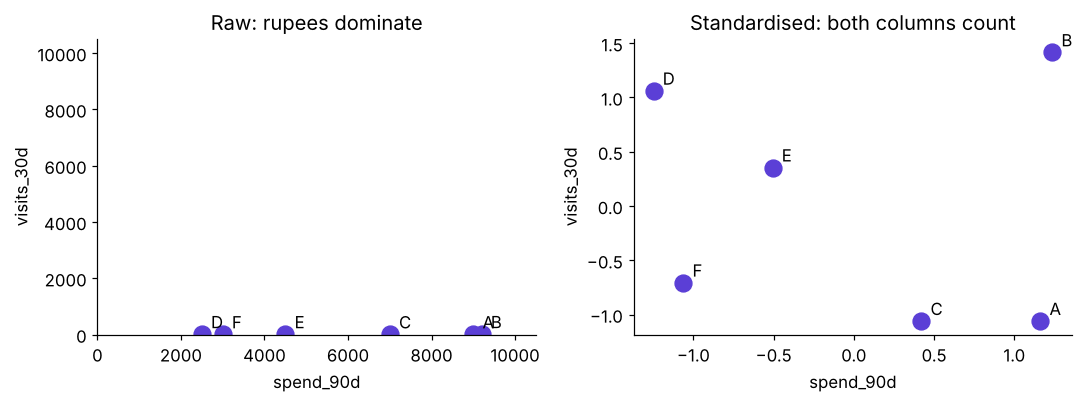

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, T, title in [(axes[0], X, "Raw: rupees dominate"), (axes[1], Z, "Standardised: both columns count")]:
    ax.scatter(T["spend_90d"], T["visits_30d"], s=120, color=VIOLET)
    for i, r in T.iterrows():
        ax.annotate(m.loc[i, "member"], (r["spend_90d"], r["visits_30d"]), xytext=(6, 4),
                    textcoords="offset points", fontsize=11)
    ax.set_title(title); ax.set_xlabel("spend_90d"); ax.set_ylabel("visits_30d")
axes[0].set_xlim(0, 10500); axes[0].set_ylim(0, 10500)   # same scale on both axes, as distance sees it
plt.tight_layout(); plt.show()

**What happened.** B. Drawn on equal axes, the raw table is a flat line: every member's
visits sit near zero beside thousands of rupees, so distance is spend alone. After
standardising, each column is measured in its own spreads, and A's nearest neighbour becomes
C, the member who also visits twice a month. The formula is `z = (value - mean) / standard
deviation`, with the mean and spread learned from training rows only.

## Which models care, and which shrug?
| Model family | Encoding a category | Scaling a number | Why |
|---|---|---|---|
| Logistic or linear regression | one-hot | yes, for the penalty and to compare coefficients | one weight per column, read in the column's units |
| Nearest neighbours, clustering | one-hot | yes, decisive | distance adds raw differences |
| Tree, forest, boosting | one-hot or an ordinal code | no | splits on thresholds, which ignore units |

A forty-value category (a city list) is still one-hot for a logistic model; forty columns
are cheap. Grouping rare values into "other" keeps it readable. Methods that replace a city
with its average outcome come later, because they can carry the target into the feature.

## What does the bank's file need?
**Predict before you run.** How many one-hot columns does `job` become? (A) 1; (B) 11;
(C) 12, with `unknown` as its own category.

In [4]:
import io, zipfile, pathlib, urllib.request
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)
f_bank = CACHE / "bank-additional-full.csv"
if not f_bank.exists():   # the week's cached loader: UCI Bank Marketing, CC BY 4.0
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
    f_bank.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
bank = pd.read_csv(f_bank, sep=";")
text_cols = [c for c in bank.columns if not pd.api.types.is_numeric_dtype(bank[c]) and c != "y"]
print("text columns:", text_cols)
print("job levels:", bank["job"].nunique(), "| unknown rows in job:", int((bank["job"] == "unknown").sum()))
print("numeric spreads (std):", bank[["age", "campaign", "euribor3m", "nr.employed"]].std().round(2).to_dict())

text columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
job levels: 12 | unknown rows in job: 330
numeric spreads (std): {'age': 10.42, 'campaign': 2.77, 'euribor3m': 1.73, 'nr.employed': 72.25}


**What happened.** C. `job` has 12 levels, `unknown` among them, and stays a category of its
own because "did not say" can carry signal. The numbers range from a spread of about 2.8 for
`campaign` to about 72 for `nr.employed`, so a logistic model's coefficients only compare
after standardising. Case 1 puts both steps inside one pipeline fitted on training rows.

In [5]:
check("every one-hot row holds exactly one 1", (onehot.sum(axis=1) == 1).all())
check("standardised columns have mean 0", bool((Z.mean().abs() < 1e-9).all()))
check("scaling changes A's nearest neighbour from B to C", nearest(X)[0] == "B" and nearest(Z)[0] == "C")
check("job one-hot gives 12 columns", bank["job"].nunique() == 12)

PASS  every one-hot row holds exactly one 1
PASS  standardised columns have mean 0
PASS  scaling changes A's nearest neighbour from B to C
PASS  job one-hot gives 12 columns


## What are the rules, and what flips each one?
1. One-hot a category for linear and distance models; a tree can take an ordinal code
   because it splits on thresholds.
2. Standardise numbers for linear and distance models; a tree ignores scale, so scaling it
   changes nothing.
3. Fit every encoder and scaler on training rows only, inside the pipeline; fitted on all
   rows, the test set shapes the features.
4. Keep `unknown` as a category when "did not say" may carry signal; drop or impute only
   when the business confirms it is noise.

Chapter 3 asks a harder question of every column: was it even known when the model runs?